# Experiment 02 - PGD Generation with Wav2Vec2
**Author:** Austin Howard \
**Date:** November 13, 2026 \
**Project:** Master's thesis research in adversarial audio \
**Repository:** ADH-Cyber/adversarial-audio

## 1. Objective
This experiment establishes a baseline for generating adversarial perturbations against an automatic speech recognition (ASR) model using Projected Gradient Descent (PGD). It evaluates whether bounded perturbations introduced into a speech waveform can degrade ASR transcription accuracy while preserving the original speech signal.

A successful experiment should demonstrate that:
- A pretrained ASR model can process and transcribe an original speech recording.
- Gradients can be computed with respect to the input waveform.
- PGD can generate a bounded adversarial perturbation.
- The perturbed waveform produces a measurablee increase in transcription error.

## 2. Environment
The experiment uses the previously configured GPU-accelerated PyTorch environment.

| Component | Configuration |
|---|---|
|Programming language|Python|
|Deep learning framework|PyTorch|
|ASR architecture|Wav2Vec2 with CTC|
|Pretrained model|facebook/wav2vec2-base-960h|
|Model parameters|94,396,320|
|Execution device|NVIDIA GPU via CUDA|
|Audio processing|Librosa|
|Evaluation|JiWER|
|Development environment|VS Code, Jupyter|

In [ ]:
%pip install -q transformers soundfile librosa jiwer
%pip install -q matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import torch
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor

model_name = "facebook/wav2vec2-base-960h"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

processor = Wav2Vec2Processor.from_pretrained(model_name)

model = Wav2Vec2ForCTC.from_pretrained(model_name)
model = model.to(device)
model.eval()

print(f"Model: {model_name}")
print(f"Device: {next(model.parameters()).device}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")


Loading weights: 100%|██████████| 212/212 [00:00<00:00, 655.66it/s]
[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: facebook/wav2vec2-base-960h
Device: cuda:0
Parameters: 94,396,320


## 3. Methodology
### 3.1 Source Audio
A short spoken proverb was recorded as the original audio sample:
> A stitch in time saves nine, but actions speak louder than words.

The original waveform serves as the reference signal for adversarial perturbation generation. The audio is loaded as mono-channel and displays its properties along with providing the original audio itself.

In [ ]:
import librosa
import numpy as np
from IPython.display import Audio, display

audio, sample_rate = librosa.load(
    "../data/original.wav",
    sr=16000,
    mono=True
)

print(f"Sample rate: {sample_rate} Hz")
print(f"Duration: {len(audio) / sample_rate:.2f} seconds")
print(f"Samples: {len(audio):,}")

display(Audio(audio, rate=sample_rate))


Sample rate: 16000 Hz
Duration: 4.10 seconds
Samples: 65,525


### 3.2 Baseline ASR Evaluation
The original waveform was processed by Wav2Vec2 to establish the baseline transcription performance.

In [ ]:
# Prepare audio for Wav2Vec2
inputs = processor(
    audio,
    sampling_rate=sample_rate,
    return_tensors="pt"
)

input_values = inputs.input_values.to(device)

# Run inference
with torch.no_grad():
    logits = model(input_values).logits

# Decode predicted tokens into text
predicted_ids = torch.argmax(logits, dim=-1)
transcription = processor.batch_decode(predicted_ids)[0]


### 3.3 Gradient Verification
Before implemeting PGD, the experiment verifies that gradients can be computed with respect to the input audio waveform. This is necessary because PGD relies on gradient information to determine how the waveform should be modified to increase transcription errors.

Wav2Vec2 uses Connectionist Temporal Classification (CTC) loss, which is a loss function designed for sequence recognition tasks where the alignment between input and output sequences is unknown. In ASR, CTC allows the model to associate audio frames with transcription characters without requiring an explicit frame-to-character alignment. It's expressed as:
$$
\mathcal{L}_{CTC}=-\log P(y\mid x)
$$
Where:
- $x$: Input audio waveform.
- $y$: Correct reference transcription.
- $P(y\mid x)$: Probability assigned to the reference transcription, summed across all valid CTC alignments.
- $\mathcal{L}_{CTC}$: Negative log-likelihood of the reference transcription.

A lower CTC loss indicates that the model assigns greater probability to the reference transcription, which is desirable for correct audio transcription.

For this experiment, the correct transcription is tokenized into CTC-compatible labels. Then the pretrained Wav2Vec2 parameters are frozen to ensure that gradients are calculated with respect to the input waveform instead of updating the model. The CTC loss is then calculate and backpropagated through the model to obtain the gradient of the loss for each audio sample:
$$
\nabla_x\mathcal{L}_{CTC}(f(x),y)
$$
The resulting gradients are evaluated for their shape, magnitude, and validity.

In [ ]:
# Correct transcription
reference = (
    "A STITCH IN TIME SAVES NINE "
    "BUT ACTIONS SPEAK LOUDER THAN WORDS"
)

# Convert reference text into CTC target tokens
labels = processor.tokenizer(
    reference,
    return_tensors="pt"
).input_ids.to(device)

# Create a differentiable copy of the audio
x = input_values.detach().clone().requires_grad_(True)

# Freeze model parameters
for parameter in model.parameters():
    parameter.requires_grad_(False)

# Calculate CTC loss
outputs = model(x, labels=labels)
loss = outputs.loss
original_ctc_loss = loss.item()

# Calculate gradient with respect to audio
loss.backward()


Successful gradient computation means that the experimental environment supports gradient-based optimization for adversarial perturbation generation. These gradients will be used to iteratively modify the waveform, maximizing CTC loss and reducing the model's probability of producing the correct transcription.

### 3.4 PGD Perturbation Generation
After verifying the gradients, PGD is implemented to generate an adversarial perturbation against the pretrained Wav2Vec2 ASR model.

PGD is an iterative gradient-based adversarial attack that modifies an input signal to maximize a specified loss function while constraining the magnitude of the perturbation. For this experiment, we use PGD to maximize CTC loss and reduce the probability that Wav2Vec2 produces the correct reference transcription. This optimization is formulated as:
$$
\max_{|\delta|\infty\leq\epsilon}\mathcal{L}{CTC}(f(x+\delta),y)
$$
Where:
- $x$: Original audio waveform.
- $\delta$: Generated adversarial perturbation.
- $f$: Pretrained Wav2Vec2 model.
- $y$: Correct reference transcription.
- $\epsilon$: Maximum permitted perturbation magnitude.
- $\mathcal{L}_{CTC}$: CTC loss.

The adversarial waveform is updated iteratively using gradient ascent:
$$
x_{t+1}'=\operatorname{clip}{[-1,1]}\left(x+\operatorname{clip}{[-\epsilon,\epsilon]}\left(x_t'+\alpha\operatorname{sign}(\nabla_{x_t'}\mathcal{L}_{CTC})-x\right)\right)
$$
Where $\alpha$ represents the step size and $t$ represents the current iteration. Additionally, the experiment uses the following hyperparameters:
| Parameter | Description |
|---|---|
| $\epsilon$ | Maximum absolute perturbation per audio sample |
| $\alpha$ | Step size for each gradient update |
| Iterations | Total number of PGD updates |
| Constraint | Limits the maximum absolute perturbation |

At each iteration, the adversarial waveform is normalized before being passed through Wav2Vex2. The resulting CTC loss is differentiated with respect to the waveform, and the sign of the gradient determines the direction of the next update. The perturbation is projected back into the permitted range ($L_infty$, in this case) and the resulting waveform is constrained to valid audio amplitudes between $-1$ and $1$. CTC loss is recorded at each iteration and plotted using matplotlib to visualize the progression during the optimization process. An overall increase in loss indicates that the model assigns decreasing probability to the correct reference transcription.

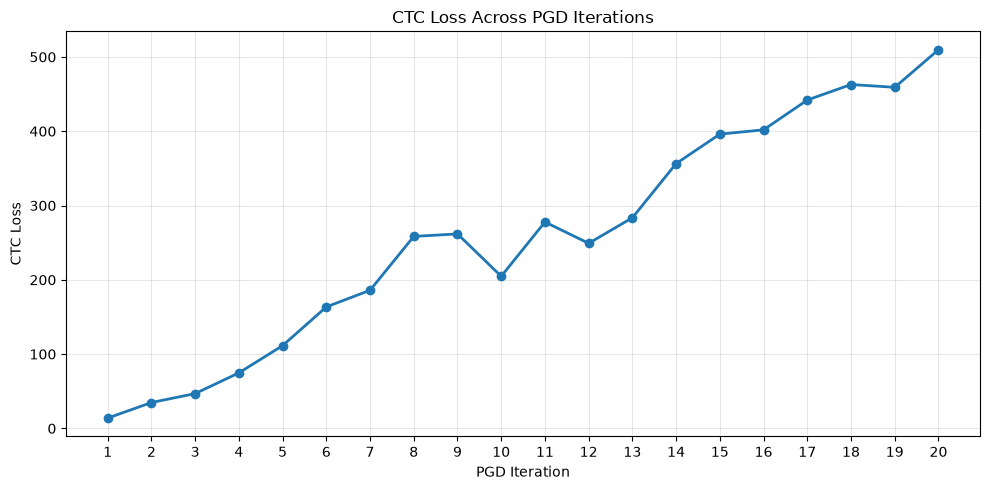

In [ ]:
import matplotlib.pyplot as plt

# PGD configuration
epsilon = 0.01
alpha = 0.001
iterations = 20

# Original waveform in [-1, 1]
original = torch.tensor(
    audio, dtype=torch.float32, device=device
).unsqueeze(0)

# Initialize adversarial waveform
adversarial = original.clone().detach()

loss_history = []

for i in range(iterations):
    adversarial.requires_grad_(True)

    # Normalize consistently with Wav2Vec2 preprocessing
    normalized = (adversarial - adversarial.mean(dim=-1, keepdim=True)) / (
        adversarial.var(dim=-1, keepdim=True).add(1e-5).sqrt()
    )

    # Forward pass
    outputs = model(normalized, labels=labels)
    loss = outputs.loss

    # Gradient ascent: maximize transcription loss
    gradient = torch.autograd.grad(
        loss, adversarial
    )[0]

    with torch.no_grad():
        adversarial = adversarial + alpha * gradient.sign()

        # Project perturbation into epsilon constraint
        delta = torch.clamp(
            adversarial - original,
            min=-epsilon,
            max=epsilon
        )

        # Constrain valid audio amplitude
        adversarial = torch.clamp(
            original + delta,
            min=-1.0,
            max=1.0
        ).detach()

    loss_history.append(loss.item())

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(loss_history) + 1),
    loss_history,
    marker="o",
    linewidth=2
)

plt.title("CTC Loss Across PGD Iterations")
plt.xlabel("PGD Iteration")
plt.ylabel("CTC Loss")
plt.xticks(range(1, len(loss_history) + 1))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Convert adversarial waveform to NumPy
adversarial_audio = adversarial.squeeze(0).cpu().numpy()

# Prepare adversarial audio for inference
adversarial_inputs = processor(
    adversarial_audio,
    sampling_rate=sample_rate,
    return_tensors="pt"
).input_values.to(device)

# Transcribe adversarial audio
with torch.no_grad():
    adversarial_logits = model(adversarial_inputs).logits

adversarial_ids = torch.argmax(adversarial_logits, dim=-1)
adversarial_transcription = processor.batch_decode(adversarial_ids)[0]

print("Original transcription:")
print(transcription)

print("\nAdversarial transcription:")
print(adversarial_transcription)

Original transcription:
A STITCH IN TIME SAVES NINE BUT ACTION SPEAK LOUDER THAN WORDS

Adversarial transcription:
A SNITCH IMPLANT STATES THE ARM OF AN ACTION SPEAK LOUDER THAN MORE REASON


In [ ]:
from jiwer import wer

baseline_wer = wer(reference, clean_decoded)
adversarial_wer = wer(reference, attack_decoded)

print(f"Baseline WER: {baseline_wer:.2%}")
print(f"Adversarial WER: {adversarial_wer:.2%}")
print(f"WER increase: {adversarial_wer - baseline_wer:.2%}")

Baseline WER: 8.33%
Adversarial WER: 91.67%
WER increase: 83.33%


## 4. Evaluation
The experiment evaluates attack effectiveness using CTC loss, Word Error Rate, Perturbation magnitude, and changes in frame-level token predictions.

Word Error Rate (WER) is calculated as:
$$
WER=\frac{S+D+I}{N}
$$

Where:
- $S$: Substitutions
- $D$: Deletions
- $I$: Insertions
- $N$: Number of reference words

## 5. Results
### 5.1 Transcription

In [ ]:
print(f"Baseline transcription:    {clean_decoded}")
print(f"Adversarial transcription: {attack_decoded}")

Baseline transcription:    A STITCH IN TIME SAVES NINE BUT ACTION SPEAK LOUDER THAN WORDS
Adversarial transcription: IN A SPIRITUAL TIME SEE ITS NME THAT ACTUAL SPEAK WHILE REASON MINDS


### 5.2 CTC Loss

In [ ]:
with torch.no_grad():
    normalized = (
        adversarial - adversarial.mean(dim=-1, keepdim=True)
    ) / (
        adversarial.var(dim=-1, keepdim=True).add(1e-5).sqrt()
    )

    adversarial_ctc_loss = model(
        normalized, labels=labels
    ).loss.item()

absolute_increase = adversarial_ctc_loss - original_ctc_loss
relative_increase = adversarial_ctc_loss / original_ctc_loss

print(f"Original CTC loss:    {original_ctc_loss:.4f}")
print(f"Adversarial CTC loss: {adversarial_ctc_loss:.4f}")
print(f"Absolute increase:    {absolute_increase:.4f}")
print(f"Relative increase:    {relative_increase:.2f}×")

Original CTC loss:    13.8557
Adversarial CTC loss: 531.2072
Absolute increase:    517.3515
Relative increase:    38.34×


### 5.2 Transcription Accuracy

In [ ]:
wer_increase = adversarial_wer - baseline_wer

print(f"{'Metric':<24} {'Value':>12}")
print("-" * 37)
print(f"{'Baseline WER':<24} {baseline_wer:>11.2%}")
print(f"{'Adversarial WER':<24} {adversarial_wer:>11.2%}")
print(f"{'Absolute WER increase':<24} {wer_increase * 100:>10.2f} pp")
print(f"{'Relative WER increase':<24} {adversarial_wer / baseline_wer:>11.2f}×")

Metric                          Value
-------------------------------------
Baseline WER                   8.33%
Adversarial WER               91.67%
Absolute WER increase         83.33 pp
Relative WER increase          11.00×


### 5.3 Perturbation Magnitude

In [ ]:
# Calculate perturbation magnitude
delta = adversarial - original

max_perturbation = delta.abs().max().item()
mean_perturbation = delta.abs().mean().item()
within_constraint = max_perturbation <= epsilon + 1e-7
waveform_modified = torch.any(delta != 0).item()

# Display results
print(f"{'Metric':<30} {'Value':>12}")
print("-" * 43)
print(f"{'Maximum absolute perturbation':<30} {max_perturbation:>12.6f}")
print(f"{'Mean absolute perturbation':<30} {mean_perturbation:>12.6f}")
print(f"{'Configured epsilon':<30} {epsilon:>12.6f}")
print(f"{'Within epsilon constraint':<30} {str(within_constraint):>12}")
print(f"{'Waveform modified':<30} {str(waveform_modified):>12}")

Metric                                Value
-------------------------------------------
Maximum absolute perturbation      0.010000
Mean absolute perturbation         0.003520
Configured epsilon                 0.010000
Within epsilon constraint              True
Waveform modified                      True


### 5.4 CTC Token Predictions

In [ ]:
# Compare frame-level CTC token predictions
with torch.no_grad():
    clean_logits = model(input_values).logits

    normalized_adversarial = (
        adversarial - adversarial.mean(dim=-1, keepdim=True)
    ) / (
        adversarial.var(dim=-1, keepdim=True).add(1e-5).sqrt()
    )

    adversarial_logits = model(normalized_adversarial).logits

clean_tokens = clean_logits.argmax(dim=-1)
adversarial_tokens = adversarial_logits.argmax(dim=-1)

# Calculate changes
total_frames = clean_tokens.numel()
changed_frames = (clean_tokens != adversarial_tokens).sum().item()
unchanged_frames = total_frames - changed_frames
change_rate = changed_frames / total_frames

# Display results
print(f"{'Metric':<30} {'Value':>12}")
print("-" * 43)
print(f"{'Total frames':<30} {total_frames:>12}")
print(f"{'Changed frames':<30} {changed_frames:>12}")
print(f"{'Unchanged frames':<30} {unchanged_frames:>12}")
print(f"{'Frame-level change rate':<30} {change_rate:>11.2%}")

Metric                                Value
-------------------------------------------
Total frames                            204
Changed frames                           86
Unchanged frames                        118
Frame-level change rate             42.16%


## 5. Conclusion
This experiment demonstrated the effectiveness of an untargeted Projected Gradient Descent (PGD) attack against a pretrained Wav2Vec2 automatic speech recognition (ASR) model. By iteratively maximizing the Connectionist Temporal Classification (CTC) loss while constraining the perturbation magnitude, the attack successfully degraded transcription accuracy without exceeding the configured perturbation limit.

The adversarial audio produced a substantial increase in CTC loss and Word Error Rate (WER) relative to the baseline recording. Changes in frame-level token predictions further demonstrated that the perturbation influenced the model's internal predictions, resulting in a significantly different decoded transcription.

The experiment establishes a functional baseline for generating and evaluating gradient-based adversarial audio perturbations using GPU-accelerated PyTorch. However, the results do not establish perceptual imperceptibility, robustness to physical acoustic transmission, or transferability across different ASR architectures.

Future experimentation will investigate targeted adversarial attacks, alternative perturbation generation methods, and the effectiveness of adversarial audio against additional ASR models. These investigations will provide a foundation for evaluating more advanced generative approaches, including GAN- and diffusion-based perturbation generation, within the broader objective of protecting clinical speech from unauthorized automated processing.

In [1]:
!jupyter nbconvert --to html --template lab "Exp2-PGDBasic.ipynb"

[NbConvertApp] Converting notebook Exp2-PGDBasic.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 566879 bytes to Exp2-PGDBasic.html
